In [3]:
import sys, os
sys.path.append(os.path.abspath(".."))
from src.bq_client import run

cohorts = run(open("../sql/03_cohort_retention.sql").read())
cohorts.head(10)

C:\Users\incha\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


,cohort_week,weeks_since,active_users,purchasers
0,2020-10-26,0,1946,8
1,2020-10-26,1,121,1
2,2020-10-26,2,31,1
3,2020-10-26,3,17,1
4,2020-10-26,4,10,0
5,2020-10-26,5,7,0
6,2020-10-26,6,4,0
7,2020-10-26,7,1,0
8,2020-10-26,8,3,0
9,2020-10-26,9,1,0


In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

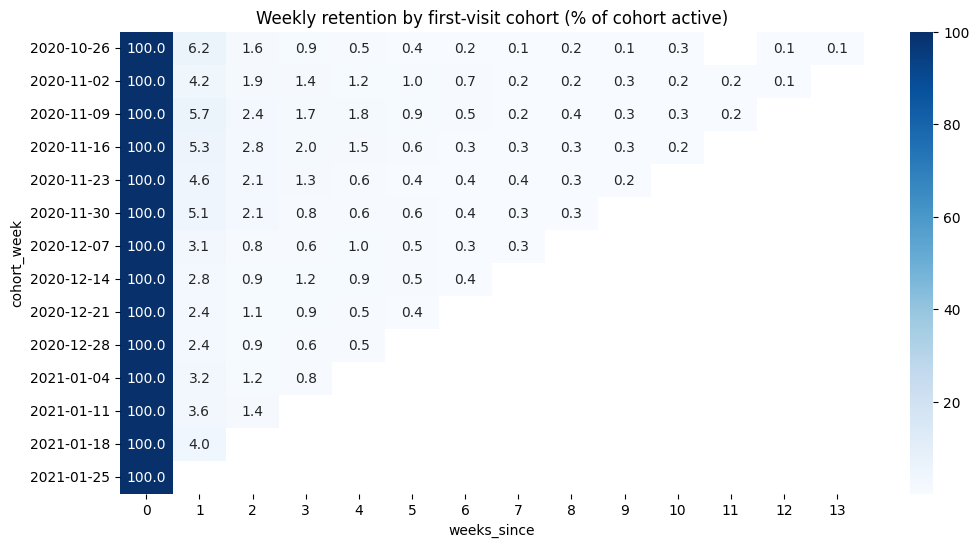

cohort_week
2020-10-26     1946
2020-11-02    16500
2020-11-09    14590
2020-11-16    16906
2020-11-23    18734
2020-11-30    21195
2020-12-07    27558
2020-12-14    24221
2020-12-21    17013
2020-12-28    16300
2021-01-04    22458
2021-01-11    21008
2021-01-18    20220
2021-01-25    18665
Name: active_users, dtype: Int64


In [5]:
sizes = cohorts[cohorts.weeks_since ==0].set_index('cohort_week')['active_users']
cohorts['retention_pct'] = cohorts.apply(
    lambda r: r.active_users / sizes[r.cohort_week] * 100, axis=1
)

retention = cohorts.pivot(index = 'cohort_week',columns = 'weeks_since', values = 'retention_pct').round(1)

plt.figure(figsize=(12, 6))
sns.heatmap(retention, annot=True, fmt='.1f', cmap='Blues')
plt.title('Weekly retention by first-visit cohort (% of cohort active)')
plt.show()

print(sizes)

In [7]:
os.makedirs("../dashboard/data", exist_ok=True)

cohort_export = cohorts[['cohort_week', 'weeks_since', 'active_users']].copy()

sizes = cohort_export[cohort_export.weeks_since == 0].set_index('cohort_week')['active_users']
cohort_export['cohort_size'] = cohort_export['cohort_week'].map(sizes)
cohort_export['retention_pct'] = (cohort_export['active_users'] / cohort_export['cohort_size'] * 100).round(1)

cohort_export = cohort_export[['cohort_week', 'weeks_since', 'active_users',
                               'cohort_size', 'retention_pct']]
cohort_export.to_csv("../dashboard/data/cohort_retention.csv", index=False)

cohort_export.head()

,cohort_week,weeks_since,active_users,cohort_size,retention_pct
0,2020-10-26,0,1946,1946,100.0
1,2020-10-26,1,121,1946,6.2
2,2020-10-26,2,31,1946,1.6
3,2020-10-26,3,17,1946,0.9
4,2020-10-26,4,10,1946,0.5
